# 05. Final Evaluation & Statistical Analysis
Tahap akhir (Phase 6) dari analisis reliabilitas LLM-as-a-Judge. Menggabungkan data dari Pilot dan Main eksperimen untuk menghasilkan metrik, uji statistik (McNemar's test), dan grafik berstandar jurnal publikasi.


In [8]:
import os
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import cohen_kappa_score
from statsmodels.stats.contingency_tables import mcnemar

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

PROJECT_ROOT = '/content/drive/MyDrive/LLMReliability'
RESULTS_DIR = os.path.join(PROJECT_ROOT, 'results')
pilot_path = os.path.join(RESULTS_DIR, 'pilot_outputs.jsonl')
main_path = os.path.join(RESULTS_DIR, 'main_outputs.jsonl')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Data Ingestion & Preprocessing


In [9]:
# 1. Load Data
loaded_results = []
for path in [pilot_path, main_path]:
    if os.path.exists(path):
        with open(path, 'r', encoding='utf-8') as f:
            for line in f:
                if line.strip():
                    loaded_results.append(json.loads(line))
        print(f"[INFO] Loaded records from {os.path.basename(path)}")
    else:
        print(f"[WARNING] {path} not found.")

print(f"[INFO] Total merged records: {len(loaded_results)}")

# 2. Parsing Logic
def parse_decision(raw_output: str) -> str:
    clean_text = str(raw_output).strip().upper()
    match = re.search(r'\b([AB])\b', clean_text)
    return match.group(1) if match else "INVALID"

for r in loaded_results:
    parsed = parse_decision(r["raw_output"])
    r["parsed_decision"] = parsed
    
    # Inverse Mapping
    if parsed == "INVALID":
        r["logical_decision"] = "INVALID"
    elif r["position"] == "AB":
        r["logical_decision"] = 1 if parsed == "A" else 2
    else:
        r["logical_decision"] = 2 if parsed == "A" else 1
        
    # Human Mapping
    if r["position"] == "AB":
        r["logical_human"] = 1 if r["human_preference"] == "A" else 2
    else:
        r["logical_human"] = 2 if r["human_preference"] == "A" else 1

df_all = pd.DataFrame(loaded_results)
# [NEW] Log Idempotency: Hapus log usang (Keep Last)
df_all = df_all.drop_duplicates(subset=['sample_id', 'prompt_id', 'position'], keep='last')
print(f"[INFO] Clean unique records after Idempotency Filter: {len(df_all)}")
invalid_rate = (len(df_all[df_all['parsed_decision'] == 'INVALID']) / len(df_all)) * 100
print(f"Total Invalid Parsing: {invalid_rate:.2f}%")

df_valid = df_all[df_all['parsed_decision'] != 'INVALID'].copy()


[INFO] Loaded records from pilot_outputs.jsonl
[INFO] Loaded records from main_outputs.jsonl
[INFO] Total merged records: 3947
[INFO] Clean unique records after Idempotency Filter: 3114
Total Invalid Parsing: 4.05%


## 2. Statistical Analysis Engine


In [10]:
# A. Accuracy & Cohen's Kappa + Bootstrap CI
def bootstrap_kappa(y_true, y_pred, n_iterations=1000, alpha=0.05):
    stats = list()
    for i in range(n_iterations):
        indices = np.random.randint(0, len(y_true), len(y_true))
        score = cohen_kappa_score(np.array(y_true)[indices], np.array(y_pred)[indices])
        stats.append(score)
    lower = np.percentile(stats, (alpha/2)*100)
    upper = np.percentile(stats, (1-alpha/2)*100)
    return lower, upper

accuracy = (df_valid['logical_decision'] == df_valid['logical_human']).mean() * 100
kappa = cohen_kappa_score(list(df_valid['logical_decision']), list(df_valid['logical_human']))
kappa_ci = bootstrap_kappa(list(df_valid['logical_human']), list(df_valid['logical_decision']))

print(f"Overall Accuracy: {accuracy:.2f}%")
print(f"Cohen's Kappa: {kappa:.3f} (95% CI: {kappa_ci[0]:.3f} - {kappa_ci[1]:.3f})")


Overall Accuracy: 52.58%
Cohen's Kappa: 0.052 (95% CI: 0.016 - 0.085)


In [11]:
# B. Position Bias & McNemar's Test
df_pos = df_valid.pivot_table(index=['sample_id', 'prompt_id'], columns='position', values='logical_decision', aggfunc='first').dropna()
position_consistency = (df_pos['AB'] == df_pos['BA']).mean() * 100
position_flip = 100 - position_consistency

print(f"Position Consistency: {position_consistency:.2f}%")
print(f"Position Flip Rate: {position_flip:.2f}%")

# McNemar Test untuk Signifikansi Pertukaran Posisi
# Tabel Kontingensi (Sama vs Beda)
# H0: Pertukaran posisi tidak mempengaruhi keputusan model secara signifikan
b = sum((df_pos['AB'] == 1) & (df_pos['BA'] == 2))
c = sum((df_pos['AB'] == 2) & (df_pos['BA'] == 1))
table = [[0, b], [c, 0]]
result = mcnemar(table, exact=False, correction=True)

print(f"McNemar's Test P-Value: {result.pvalue:.5f}")
if result.pvalue < 0.05:
    print("=> SIGNIFIKAN: Pertukaran posisi secara absolut mengubah preferensi model!")


# [NEW] First-Position Preference Rate
first_pos_rate = (df_valid['parsed_decision'] == 'A').mean() * 100
print(f"First-position preference rate: {first_pos_rate:.2f}%")


Position Consistency: 68.84%
Position Flip Rate: 31.16%
McNemar's Test P-Value: 0.00002
=> SIGNIFIKAN: Pertukaran posisi secara absolut mengubah preferensi model!
First-position preference rate: 47.42%


In [12]:
# C. Pairwise Prompt Flip Rate
df_prompt = df_valid[df_valid['position'] == 'AB'].pivot_table(index='sample_id', columns='prompt_id', values='logical_decision').dropna()
flip_p1_p2 = (df_prompt['P1'] != df_prompt['P2']).mean() * 100
flip_p1_p3 = (df_prompt['P1'] != df_prompt['P3']).mean() * 100
flip_p2_p3 = (df_prompt['P2'] != df_prompt['P3']).mean() * 100

print(f"Prompt Flip Rate (P1 vs P2): {flip_p1_p2:.2f}%")
print(f"Prompt Flip Rate (P1 vs P3): {flip_p1_p3:.2f}%")
print(f"Prompt Flip Rate (P2 vs P3): {flip_p2_p3:.2f}%")

Prompt Flip Rate (P1 vs P2): 14.86%
Prompt Flip Rate (P1 vs P3): 19.51%
Prompt Flip Rate (P2 vs P3): 19.29%


## 3. Visualisasi Publikasi (Figures)


/tmp/ipykernel_2473/1170625907.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  prompt_acc = df_valid.groupby('prompt_id').apply(lambda x: (x['logical_decision'] == x['logical_human']).mean()).reset_index(name='accuracy')
/tmp/ipykernel_2473/1170625907.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=prompt_acc, x='prompt_id', y='accuracy', ax=axes[0,0], palette='Blues')
/tmp/ipykernel_2473/1170625907.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to

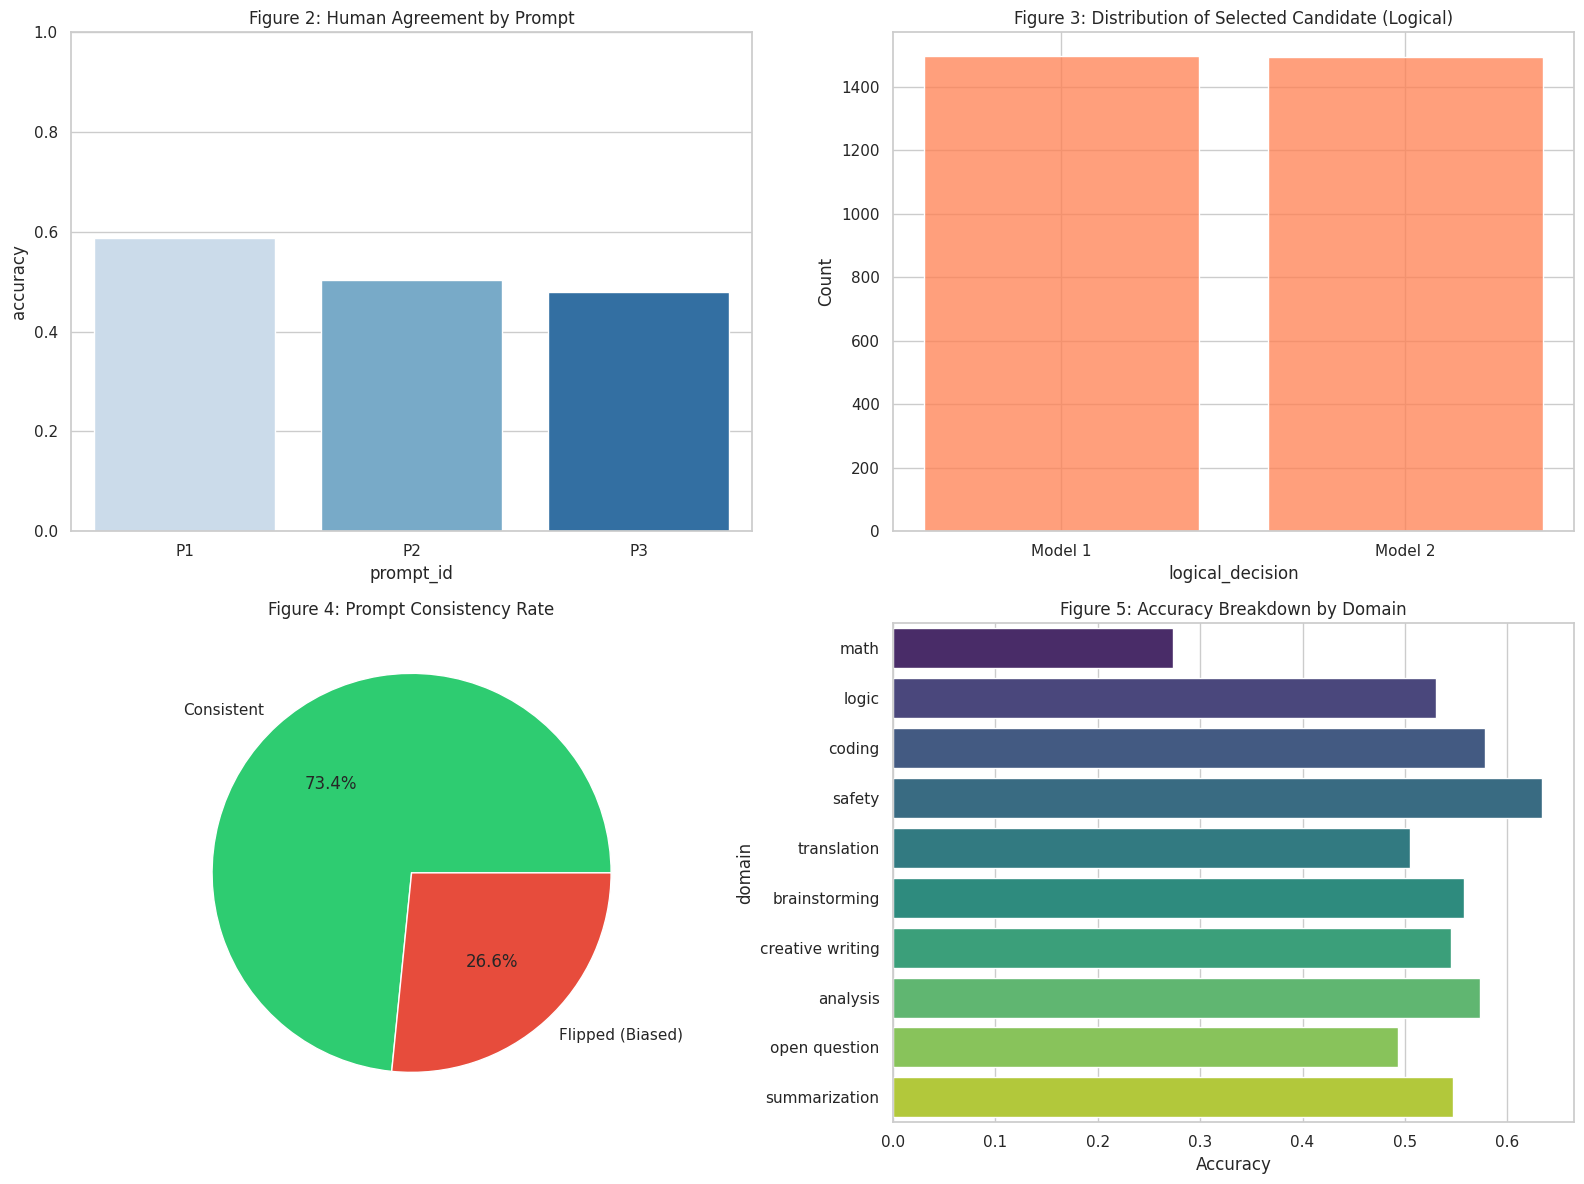

In [13]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Human Agreement by Prompt
prompt_acc = df_valid.groupby('prompt_id').apply(lambda x: (x['logical_decision'] == x['logical_human']).mean()).reset_index(name='accuracy')
sns.barplot(data=prompt_acc, x='prompt_id', y='accuracy', ax=axes[0,0], palette='Blues')
axes[0,0].set_title("Figure 2: Human Agreement by Prompt")
axes[0,0].set_ylim(0, 1)

# 2. Position Consistency Breakdown
sns.histplot(df_valid['logical_decision'], ax=axes[0,1], discrete=True, shrink=0.8, color='coral')
axes[0,1].set_title("Figure 3: Distribution of Selected Candidate (Logical)")
axes[0,1].set_xticks([1, 2])
axes[0,1].set_xticklabels(['Model 1', 'Model 2'])

# 3. Prompt Consistency Rate
prompt_group = df_valid.groupby(['sample_id', 'position'])['logical_decision'].nunique()
prompt_consistency = (prompt_group == 1).mean() * 100
axes[1,0].pie([prompt_consistency, 100-prompt_consistency], labels=['Consistent', 'Flipped (Biased)'], autopct='%1.1f%%', colors=['#2ecc71', '#e74c3c'])
axes[1,0].set_title("Figure 4: Prompt Consistency Rate")

# 4. Domain Breakdown Accuracy
df_valid['is_correct'] = (df_valid['logical_decision'] == df_valid['logical_human']).astype(int)
sns.barplot(data=df_valid, y='domain', x='is_correct', orient='h', ax=axes[1,1], palette='viridis', errorbar=None)
axes[1,1].set_title("Figure 5: Accuracy Breakdown by Domain")
axes[1,1].set_xlabel("Accuracy")

plt.tight_layout()
plt.show()


## 4. Ekspor Metrik Final


In [14]:
final_metrics = {
    "total_samples": len(df_valid),
    "accuracy_percent": round(accuracy, 2),
    "cohens_kappa": round(kappa, 3),
    "kappa_ci_lower": round(kappa_ci[0], 3),
    "kappa_ci_upper": round(kappa_ci[1], 3),
    "position_consistency_percent": round(position_consistency, 2),
    "position_flip_rate_percent": round(position_flip, 2),
    "mcnemar_p_value": result.pvalue,
    "prompt_consistency_percent": round(prompt_consistency, 2),
    "first_pos_rate_percent": round(first_pos_rate, 2),
    "prompt_flip_p1_p2": round(flip_p1_p2, 2),
    "prompt_flip_p1_p3": round(flip_p1_p3, 2),
    "prompt_flip_p2_p3": round(flip_p2_p3, 2)
}

export_path = os.path.join(RESULTS_DIR, 'final_evaluation_metrics.json')
with open(export_path, 'w') as f:
    json.dump(final_metrics, f, indent=4)
print(f"Final metrics exported to: {export_path}")


Final metrics exported to: /content/drive/MyDrive/LLMReliability/results/final_evaluation_metrics.json
